# Search

Run top to bottom. Inputs are in `../data`; figures are displayed inline.
Input checksums can be verified with `python scripts/render_figures.py --all`.

In [2]:
from io import BytesIO
from IPython.display import display, Image as InlineImage


import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Lato", "Arial", "DejaVu Sans", "Liberation Sans"]
plt.rcParams["svg.fonttype"] = "none"

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'scripts').is_dir())
CANON = ROOT / "data/plot_tables"
REFRESH = CANON / "steam_current"
SEARCH = ROOT / "data/search_results"
EXPERIMENT_SEARCH = SEARCH / "steam_final/current"
AF_TIMING_NAME = 'timing_64_warm30.json'

METHOD_ORDER = [
    "STEAM", "STEAM (domain)", "MMseqs2", "ProstT5–Foldseek",
    "Foldseek", "Reseek (Superfamily mode)", "EBA", "DALI",
]
METHOD_LABELS = {
    "steam": "STEAM", "steam_domain": "STEAM (domain)",
    "mmseqs2": "MMseqs2", "prostt5_foldseek": "ProstT5–Foldseek",
    "foldseek": "Foldseek", "reseek": "Reseek (Superfamily mode)",
    "eba": "EBA", "dali": "DALI",
}
COLORS = {
    "STEAM": "#654183", "STEAM (domain)": "#9672b2",
    "MMseqs2": "#3E88B7", "Foldseek": "#d84b48",
    "ProstT5–Foldseek": "#df951e",
    "Reseek (Superfamily mode)": "#27756E",
    "DALI": "#687589", "EBA": "#ae86c2",
}
MARKERS = {
    "STEAM": "o", "STEAM (domain)": "h", "MMseqs2": "P",
    "Foldseek": "X", "ProstT5–Foldseek": "^",
    "Reseek (Superfamily mode)": "D", "DALI": "v", "EBA": "s",
}
DASHES = {
    "STEAM": "-", "STEAM (domain)": (0, (4, 1.7)),
    "MMseqs2": (0, (5, 2.5)), "Foldseek": (0, (3.2, 1.5, 1.0, 1.5)),
    "ProstT5–Foldseek": (0, (2.3, 1.4)),
    "Reseek (Superfamily mode)": (0, (5, 1.5, 1, 1.5)),
    "DALI": (0, (.8, 1.8)), "EBA": (0, (.8, 3.0)),
}
PAPER = {
    "font_size": 7.0, "tick_size": 6.5, "legend_size": 6.3,
    "panel_size": 8.0, "dpi": 450, "line_width": 1.15,
    "marker_size": 2.0,
}


# SCOP conversion-context comparison; AFMD/MMMD already use full protein inputs.
PROST_CONTEXT = CANON / "scop/search/prostt5_full_chain"
PROST_DOMAIN_LABEL = "ProstT5–Foldseek (domain)"
METHOD_ORDER.insert(METHOD_ORDER.index("ProstT5–Foldseek") + 1, PROST_DOMAIN_LABEL)
METHOD_LABELS["prostt5_foldseek"] = PROST_DOMAIN_LABEL
METHOD_LABELS["prostt5_foldseek_full_chain"] = "ProstT5–Foldseek"
COLORS[PROST_DOMAIN_LABEL] = "#c68d45"
MARKERS[PROST_DOMAIN_LABEL] = "v"
DASHES[PROST_DOMAIN_LABEL] = (0, (2.3, 1.4))
DASHES["ProstT5–Foldseek"] = "-"

### Input tables and plot styling

In [3]:
def prost_context_table(name):
    return pd.read_csv(PROST_CONTEXT / name, sep="\t")

def read_json(path: Path) -> dict:
    return json.loads(path.read_text())


def paper_rc() -> None:
    mpl.rcParams.update({
        "font.family": "Lato", "font.sans-serif": ["Lato", "Arial", "DejaVu Sans"],
        "font.size": PAPER["font_size"], "font.weight": "normal",
        "axes.labelweight": "normal", "axes.labelsize": PAPER["font_size"],
        "axes.labelpad": 2.5, "xtick.labelsize": PAPER["tick_size"],
        "ytick.labelsize": PAPER["tick_size"],
        "legend.fontsize": PAPER["legend_size"], "legend.frameon": False,
        "legend.handlelength": 1.5, "legend.labelspacing": .35,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.linewidth": .65, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
        "xtick.major.width": .6, "ytick.major.width": .6,
        "xtick.major.pad": 2, "ytick.major.pad": 2,
        "grid.linewidth": .45, "grid.color": "#dedde1",
        "path.simplify": False, "agg.path.chunksize": 20000,
        "savefig.bbox": None, "svg.fonttype": "none",
    })

def clean_axis(axis) -> None:
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(labelsize=PAPER["tick_size"], width=.6, length=2.5)
    for spine in axis.spines.values():
        spine.set_linewidth(.65)

def panel_letter(fig, axis, letter: str, dx: float = -.20, dy: float = .07) -> None:
    bounds = axis.get_position(original=True)
    width, height = fig.get_size_inches()
    fig.text(bounds.x0 + dx / width, bounds.y1 + dy / height, letter,
             ha="left", va="bottom", fontsize=PAPER["panel_size"],
             fontweight="bold")

def step(axis, x, y, label: str, *, where: str = "post", markers: int = 11,
         linewidth: float | None = None):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    markevery = np.unique(np.linspace(0, len(x) - 1, min(markers, len(x)), dtype=int))
    if label in ('STEAM', 'STEAM (domain)') and len(x) > 1:
        lo, hi = float(x.min()), float(x.max())
        positions = np.linspace(lo + .025 * (hi-lo), hi - .025 * (hi-lo), markers)
        descending = x[0] > x[-1]
        ordered = x[::-1] if descending else x
        indices = np.clip(np.searchsorted(ordered, positions, side='right') - 1, 0, len(x)-1)
        markevery = np.unique(len(x)-1-indices if descending else indices)
    line = axis.step(
        x, y, where=where, label=label, color=COLORS[label],
        linestyle=DASHES[label], linewidth=linewidth or PAPER["line_width"],
        marker=MARKERS[label], markersize=PAPER["marker_size"],
        markevery=markevery,
    )[0]
    line.get_path().should_simplify = False
    if label in ('STEAM', 'STEAM (domain)'):
        line.set_zorder(5 if label == 'STEAM' else 6)
    return line

def ordered_legend(axis, *, labels: dict[str, str] | None = None, **kwargs) -> None:
    handles, names = axis.get_legend_handles_labels()
    pairs = [(handle, name) for handle, name in zip(handles, names)
             if name in METHOD_ORDER]
    pairs.sort(key=lambda pair: METHOD_ORDER.index(pair[1]))
    if not pairs:
        return
    handles, names = zip(*pairs)
    shown = [labels.get(name, name) if labels else name for name in names]
    axis.legend(handles, shown, **kwargs)

### SCOP sensitivity and precision–recall (A–B)

In [4]:
def load_scop_curves() -> pd.DataFrame:
    selected = []
    path = REFRESH / "scop/curves.tsv"
    for chunk in pd.read_csv(path, sep="\t", chunksize=500_000):
        rows = chunk.loc[
            chunk.hierarchy.eq("family")
            & chunk.metric.isin({"sensitivity", "weighted_pr"})
        ]
        if not rows.empty:
            selected.append(rows)
    refreshed = pd.concat(selected, ignore_index=True)
    return pd.concat([refreshed, prost_context_table("curves.tsv")], ignore_index=True)

def draw_scop_curves(axis, curves, metric, markers=11):
    frame = curves.loc[curves.metric.eq(metric) & curves.hierarchy.eq("family")]
    for method in ("steam", "steam_domain", "mmseqs2", "prostt5_foldseek",
                   "prostt5_foldseek_full_chain", "foldseek", "reseek", "eba", "dali"):
        if method == "eba":
            rows = pd.read_csv(CANON / f"scop/search/domain_only/eba_family_{metric}.tsv", sep="\t")
        else:
            rows = frame.loc[frame.method.eq(method)].sort_values("point_index", kind="stable")
        step(axis, rows.x, rows.y, METHOD_LABELS[method], markers=markers)
    axis.set_xticks([0, .5, 1])
    axis.set_yticks([0, .5, 1])
    axis.grid(axis="y", linestyle="--", alpha=.20)

def draw_scop_A(axis, curves):
    draw_scop_curves(axis, curves, "sensitivity")
    axis.set(xlim=(-.025, 1.025), ylim=(-.025, 1.025),
             xlabel="Fraction of queries", ylabel="1st-FP sensitivity")
    ordered_legend(
        axis,
        labels={"STEAM": "STEAM", "STEAM (domain)": "STEAM (domain)",
                "ProstT5–Foldseek": "ProstT5–FS",
                PROST_DOMAIN_LABEL: "ProstT5–FS (domain)",
                "Reseek (Superfamily mode)": "Reseek",
                "EBA": "EBA (domain)"},
        frameon=False, ncol=1, fontsize=5.0, loc="lower left",
        bbox_to_anchor=(.015, .025), borderaxespad=0,
        handlelength=1.4, handletextpad=.4, labelspacing=.13,
    )

def draw_scop_B(axis, curves: pd.DataFrame) -> None:
    draw_scop_curves(axis, curves, "weighted_pr", markers=9)
    axis.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall", ylabel="Weighted precision")

def load_scop_calibration():
    refresh = REFRESH / "evalues/scop"
    frames = []
    for table, full_chain in (("curves.tsv", "calibration.tsv"),
                              ("operating_points.tsv", "operating_points.tsv")):
        frame = pd.read_csv(refresh / table, sep="\t")
        frame = frame.replace({"method": {"ProstT5–Foldseek": PROST_DOMAIN_LABEL}})
        frames.append(pd.concat([frame, prost_context_table(full_chain)], ignore_index=True))
    return frames



### E-value calibration and SCOP classes (C–D)

In [5]:
def draw_calibration(axis, curves: pd.DataFrame, points: pd.DataFrame, *, upper: float) -> None:
    for method in ["STEAM", "MMseqs2", "ProstT5–Foldseek", PROST_DOMAIN_LABEL, "Foldseek",
                   "Reseek (Superfamily mode)"]:
        frame = curves.loc[curves.method.eq(method)].sort_values("evalue_cutoff", kind="stable")
        line = axis.step(frame.evalue_cutoff, frame.observed_errors_per_query,
                         where="post", color=COLORS[method], linestyle=DASHES[method],
                         linewidth=PAPER["line_width"], label=method)[0]
        line.get_path().should_simplify = False
        operating = points.loc[points.method.eq(method)]
        axis.plot(operating.evalue_cutoff, operating.observed_errors_per_query,
                  linestyle="none", marker=MARKERS[method], markersize=2.4,
                  markeredgewidth=.25, color=COLORS[method])
    axis.plot([1e-3, upper], [1e-3, upper], color="#737373", linestyle=":",
              linewidth=.8, label="Ideal")
    axis.set(xscale="log", yscale="log", xlim=(1e-3, upper), ylim=(1e-3, upper),
             xlabel="E-value cutoff",
             ylabel="False positives / query")
    axis.minorticks_off()
    axis.grid(which="major", alpha=.16)
    axis.legend([Line2D([0], [0], color="#737373", linestyle=":", linewidth=.8)],
                ["Ideal"], frameon=False, fontsize=6.1, loc="upper left",
                handlelength=1.5)

def load_class_weighted_ap() -> pd.DataFrame:
    """Balanced family/remote-superfamily AP on the common eligible cohort."""
    methods = ("steam", "steam_domain", "mmseqs2", "prostt5_foldseek", "prostt5_foldseek_full_chain",
               "foldseek", "reseek", "eba", "dali")
    frames = []
    for method in methods:
        if method == "eba":
            path = CANON / "scop/search/domain_only/hierarchical_weighted_pr/eba_summary.tsv"
        else:
            path = REFRESH / f"scop/hierarchical_weighted_pr/{method}_summary.tsv"
        frame = (prost_context_table(f"hierarchical_weighted_pr/{method}_summary.tsv")
                 if method == "prostt5_foldseek_full_chain" else pd.read_csv(path, sep="\t"))
        frame = frame.loc[frame.scop_class.ne("all")]
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)

def draw_class_D(axis, table: pd.DataFrame) -> None:
    methods = ["steam", "steam_domain", "mmseqs2", "prostt5_foldseek", "prostt5_foldseek_full_chain",
               "foldseek", "reseek", "eba", "dali"]
    classes = list("abcdefg")
    labels = [METHOD_LABELS[method] for method in methods]
    counts, matrix = [], []
    for scop_class in classes:
        rows = table.loc[table.scop_class.eq(scop_class)]
        counts.append(int(rows.eligible_queries.iloc[0]))
        values = rows.set_index("method").loc[methods, "hierarchical_weighted_ap"].to_numpy(float)
        matrix.append(values)
    matrix = np.asarray(matrix)
    for i, values in enumerate(matrix):
        axis.plot([values.min(), values.max()], [i, i], color="#b8b6bb", linewidth=.65, zorder=1)
        for rank, j in enumerate(np.argsort(values, kind="stable")):
            label = labels[j]
            marker_y = i + (-.115 if rank % 2 == 0 else .115)
            axis.plot([values[j], values[j]], [i, marker_y], color=COLORS[label],
                      linewidth=.55, alpha=.85, zorder=2)
            axis.plot(values[j], marker_y, linestyle="none", marker=MARKERS[label],
                      markersize=3.2, color=COLORS[label], markeredgecolor="white",
                      markeredgewidth=.30, zorder=3 + j * .01)
    class_names = ["α", "β", "α/β", "α+β", "Multi", "TM", "Small"]
    axis.set_yticks(range(7), [f"{name}\n(n={count:,})" for name, count in zip(class_names, counts)],
                    fontsize=5.0)
    axis.set(ylim=(6.45, -.45), xlim=(0, 1),
             xlabel="Family + superfamily weighted AP")
    axis.set_xticks([0, .25, .5, .75, 1])
    axis.grid(axis="x", alpha=.2)
    axis.tick_params(length=2, pad=2)

### AF multidomain sensitivity and runtime (E–F)

In [6]:
def af_metric_paths() -> dict[str, Path]:
    root = CANON / "af_multidomain"
    return {
        "STEAM": REFRESH / "af_multidomain/steam/metrics.json",
        "MMseqs2": root / "mmseqs/metrics.json",
        "Foldseek": root / "foldseek/metrics.json",
        "ProstT5–Foldseek": root / "prostt5_foldseek/metrics.json",
        "Reseek (Superfamily mode)": root / "reseek/metrics.json",
        "DALI": root / "dali/metrics.json", "EBA": root / "eba/metrics.json",
    }

def draw_af_E(axis) -> None:
    inset = axis.inset_axes([.69, .52, .27, .45])
    for label, path in af_metric_paths().items():
        result = read_json(path)
        metric = result["upstream_replay"]
        coverage, quality = metric["coverage"], metric["quality"]
        axis.plot(coverage["tp_hits"], coverage["query_coverage"],
                  color=COLORS[label], linestyle=DASHES[label], marker=MARKERS[label],
                  markersize=2.3, linewidth=1.15, label=label)
        inset.scatter(quality["sensitivity"], quality["selectivity"],
                      color=COLORS[label], marker=MARKERS[label], s=18,
                      linewidth=.30, edgecolors="white")
    axis.set(xlabel="TP hits to 1st FP", ylabel="Query coverage", ylim=(0, 1))
    axis.set_yticks([0, .5, 1])
    inset.set(xlabel="Sensitivity", ylabel="Precision", xlim=(0, 1), ylim=(.5, 1))
    inset.set_xticks([0, .5, 1])
    inset.set_yticks([.5, .75, 1])
    inset.tick_params(labelsize=5.0, length=1.7, pad=1)
    inset.xaxis.label.set_size(5.3)
    inset.yaxis.label.set_size(5.3)
    inset.patch.set_facecolor("white")
    inset.patch.set_alpha(.92)
    for spine in inset.spines.values():
        spine.set_linewidth(.45)

def draw_af_F(axis) -> None:
    timing = read_json(CANON / "af_multidomain/timing.json")
    gentle_timing = read_json(
        EXPERIMENT_SEARCH / "af_multidomain" / AF_TIMING_NAME
    )
    measured = {
        "STEAM": gentle_timing["median_seconds"],
        "MMseqs2": timing["methods"]["mmseqs"]["median_seconds"],
        "Foldseek": timing["methods"]["foldseek"]["median_seconds"],
        "ProstT5–Foldseek": timing["methods"]["prostt5_foldseek"]["median_seconds"],
        "Reseek (Superfamily mode)": timing["methods"]["reseek_superfamily"]["median_seconds"],
    }
    dali = read_json(SEARCH / "af_multidomain/dali/run.json")
    eba = read_json(SEARCH / "af_multidomain/eba/run.json")
    estimated = {"DALI": dali["ideal_64_cpu_hours"] * 3600,
                 "EBA": eba["sum_shard_wall_seconds"] / 64}
    display = {"STEAM": "STEAM", "MMseqs2": "MMseqs2",
               "Foldseek": "Foldseek", "ProstT5–Foldseek": "ProstT5",
               "Reseek (Superfamily mode)": "Reseek", "DALI": "DALI", "EBA": "EBA"}
    label_heights = {"STEAM": 1.55, "MMseqs2": 2.8, "ProstT5–Foldseek": 5.5,
                     "Foldseek": 10.4, "Reseek (Superfamily mode)": 20.5}
    axis.plot([.19, .19], [1, 1e5], color="#b9b9bf", lw=.65, zorder=1)
    for name, seconds in {**measured, **estimated}.items():
        label_y = label_heights.get(name, seconds)
        open_marker = name in estimated
        ratio = seconds / measured["STEAM"]
        ratio_label = "1×" if name == "STEAM" else (
            f"{ratio:.1f}×" if ratio < 100 else f"{ratio:,.0f}×"
        )
        axis.plot([.19, .27], [seconds, label_y], color=COLORS[name], lw=.65,
                  linestyle=DASHES[name], zorder=2)
        axis.scatter(.19, seconds, s=12, marker=MARKERS[name],
                     facecolor="white" if open_marker else COLORS[name],
                     edgecolor=COLORS[name] if open_marker else "white",
                     linewidth=.65 if open_marker else .25, zorder=4)
        axis.text(.28, label_y, f"{display[name]} {ratio_label}",
                  color=COLORS[name], fontsize=5.45,
                  va="center", ha="left")
    axis.set(yscale="log", ylim=(1, 1e5), xlim=(0, 1), ylabel="Search time")
    axis.set_xticks([])
    axis.set_yticks([1, 60, 3600, 86400], ["1 s", "1 min", "1 h", "1 d"])
    axis.minorticks_off()
    axis.spines[["top", "right", "bottom"]].set_visible(False)

### MMseqs multidomain calibration and figure layout

In [7]:
def draw_mmmd_H(axis, results: dict[str, dict]) -> None:
    for method in ["STEAM", "MMseqs2", ITER3_LABEL, "ProstT5–Foldseek"]:
        result = results[method]
        line = axis.step(
            result["predicted_errors_per_query"], result["observed_errors_per_query"],
            where="post", color=COLORS[method], linestyle=DASHES[method],
            linewidth=PAPER["line_width"], label=method,
        )[0]
        line.get_path().should_simplify = False
        cutoffs, observed = [], []
        for row in result["operating_points"]:
            cutoffs.append(row.get("evalue_cutoff",
                                   row.get("predicted_errors_per_query_cutoff")))
            observed.append(row["observed_errors_per_query"])
        axis.plot(cutoffs, observed, linestyle="none", marker=MARKERS[method],
                  markersize=2.4, markeredgewidth=.25, color=COLORS[method])
    axis.plot([1e-3, 1e4], [1e-3, 1e4], color="#737373", linestyle=":",
              linewidth=.8, label="Ideal")
    axis.set(xscale="log", yscale="log", xlim=(1e-3, 1e4), ylim=(1e-3, 1e4),
             xlabel="E-value cutoff",
             ylabel="False positives / query")
    axis.minorticks_off()
    axis.grid(which="major", alpha=.16)
    axis.legend([Line2D([0], [0], color="#737373", linestyle=":", linewidth=.8)],
                ["Ideal"], frameon=False, fontsize=6.1, loc="upper left",
                handlelength=1.5)


def render() -> Path:
    paper_rc()
    layout = {"size": (7.2, 6.75), "left": .080, "right": .968,
              "top_row": (4.84, 6.34), "middle_row": (2.72, 4.22),
              "bottom_row": (.60, 2.10), "gutter": .25}
    fig = plt.figure(figsize=layout["size"], dpi=150)
    top = fig.add_gridspec(
        1, 3, left=layout["left"], right=layout["right"],
        bottom=layout["top_row"][0] / layout["size"][1],
        top=layout["top_row"][1] / layout["size"][1],
        width_ratios=(1.23, 1.23, .91), wspace=layout["gutter"],
    )
    middle = fig.add_gridspec(
        1, 3, left=layout["left"], right=layout["right"],
        bottom=layout["middle_row"][0] / layout["size"][1],
        top=layout["middle_row"][1] / layout["size"][1],
        width_ratios=(1.0, 1.20, .58), wspace=.17,
    )
    bottom = fig.add_gridspec(
        1, 3, left=layout["left"], right=layout["right"],
        bottom=layout["bottom_row"][0] / layout["size"][1],
        top=layout["bottom_row"][1] / layout["size"][1],
        width_ratios=(1.05, .90, 1.05), wspace=.17,
    )
    A, B, C = [fig.add_subplot(top[0, i]) for i in range(3)]
    D, E, F = [fig.add_subplot(middle[0, i]) for i in range(3)]
    G, H, I = [fig.add_subplot(bottom[0, i]) for i in range(3)]

    curves = load_scop_curves()
    draw_scop_A(A, curves)
    draw_scop_B(B, curves)
    c_curves, c_points = load_scop_calibration()
    draw_calibration(C, c_curves, c_points, upper=1e3)
    C.set_xticks([1e-3, 1e-1, 1e1, 1e3])
    C.set_yticks([1e-3, 1e-1, 1e1, 1e3])
    draw_class_D(D, load_class_weighted_ap())
    draw_af_E(E)
    draw_af_F(F)
    draw_mmmd_G(G)
    draw_mmmd_H(H, load_mmmd_evalues())
    H.set_xticks([1e-3, 1e-1, 1e1, 1e3])
    H.set_yticks([1e-3, 1e-1, 1e1, 1e3])
    draw_first_fp_I(I)

    for axis in (A, B, C, D, E, F, G, H, I):
        clean_axis(axis)
    F.tick_params(axis="y", labelsize=5.7, length=2, pad=1)
    for axis, letter in zip((A, B, C, D, E, F, G, H, I), "ABCDEFGHI"):
        panel_letter(fig, axis, letter)

    with BytesIO() as image_buffer:
        fig.savefig(image_buffer, format='png', dpi=PAPER["dpi"], facecolor="white")
        plt.close(fig)
        display(InlineImage(data=image_buffer.getvalue()))


MMMD_MATCHED = CANON / "figure2_iterations/mmmd_matched"
MMMD_TIMING = SEARCH / "figure2_iterations/mmmd"
ITER3_LABEL = 'MMseqs2 (3 iter.)'
ITER3_RECEIPT = MMMD_TIMING/'mmseqs_3iter/run.json'
ITER3_TABLES = MMMD_MATCHED/'mmseqs_3iter/three_pass'
ITER3_RUN = read_json(ITER3_RECEIPT)
COLORS[ITER3_LABEL] = '#9BDCF5'
MARKERS[ITER3_LABEL] = 's'
DASHES[ITER3_LABEL] = (0,(2.5,1,1,1))

### MMseqs multidomain comparisons (G–I)

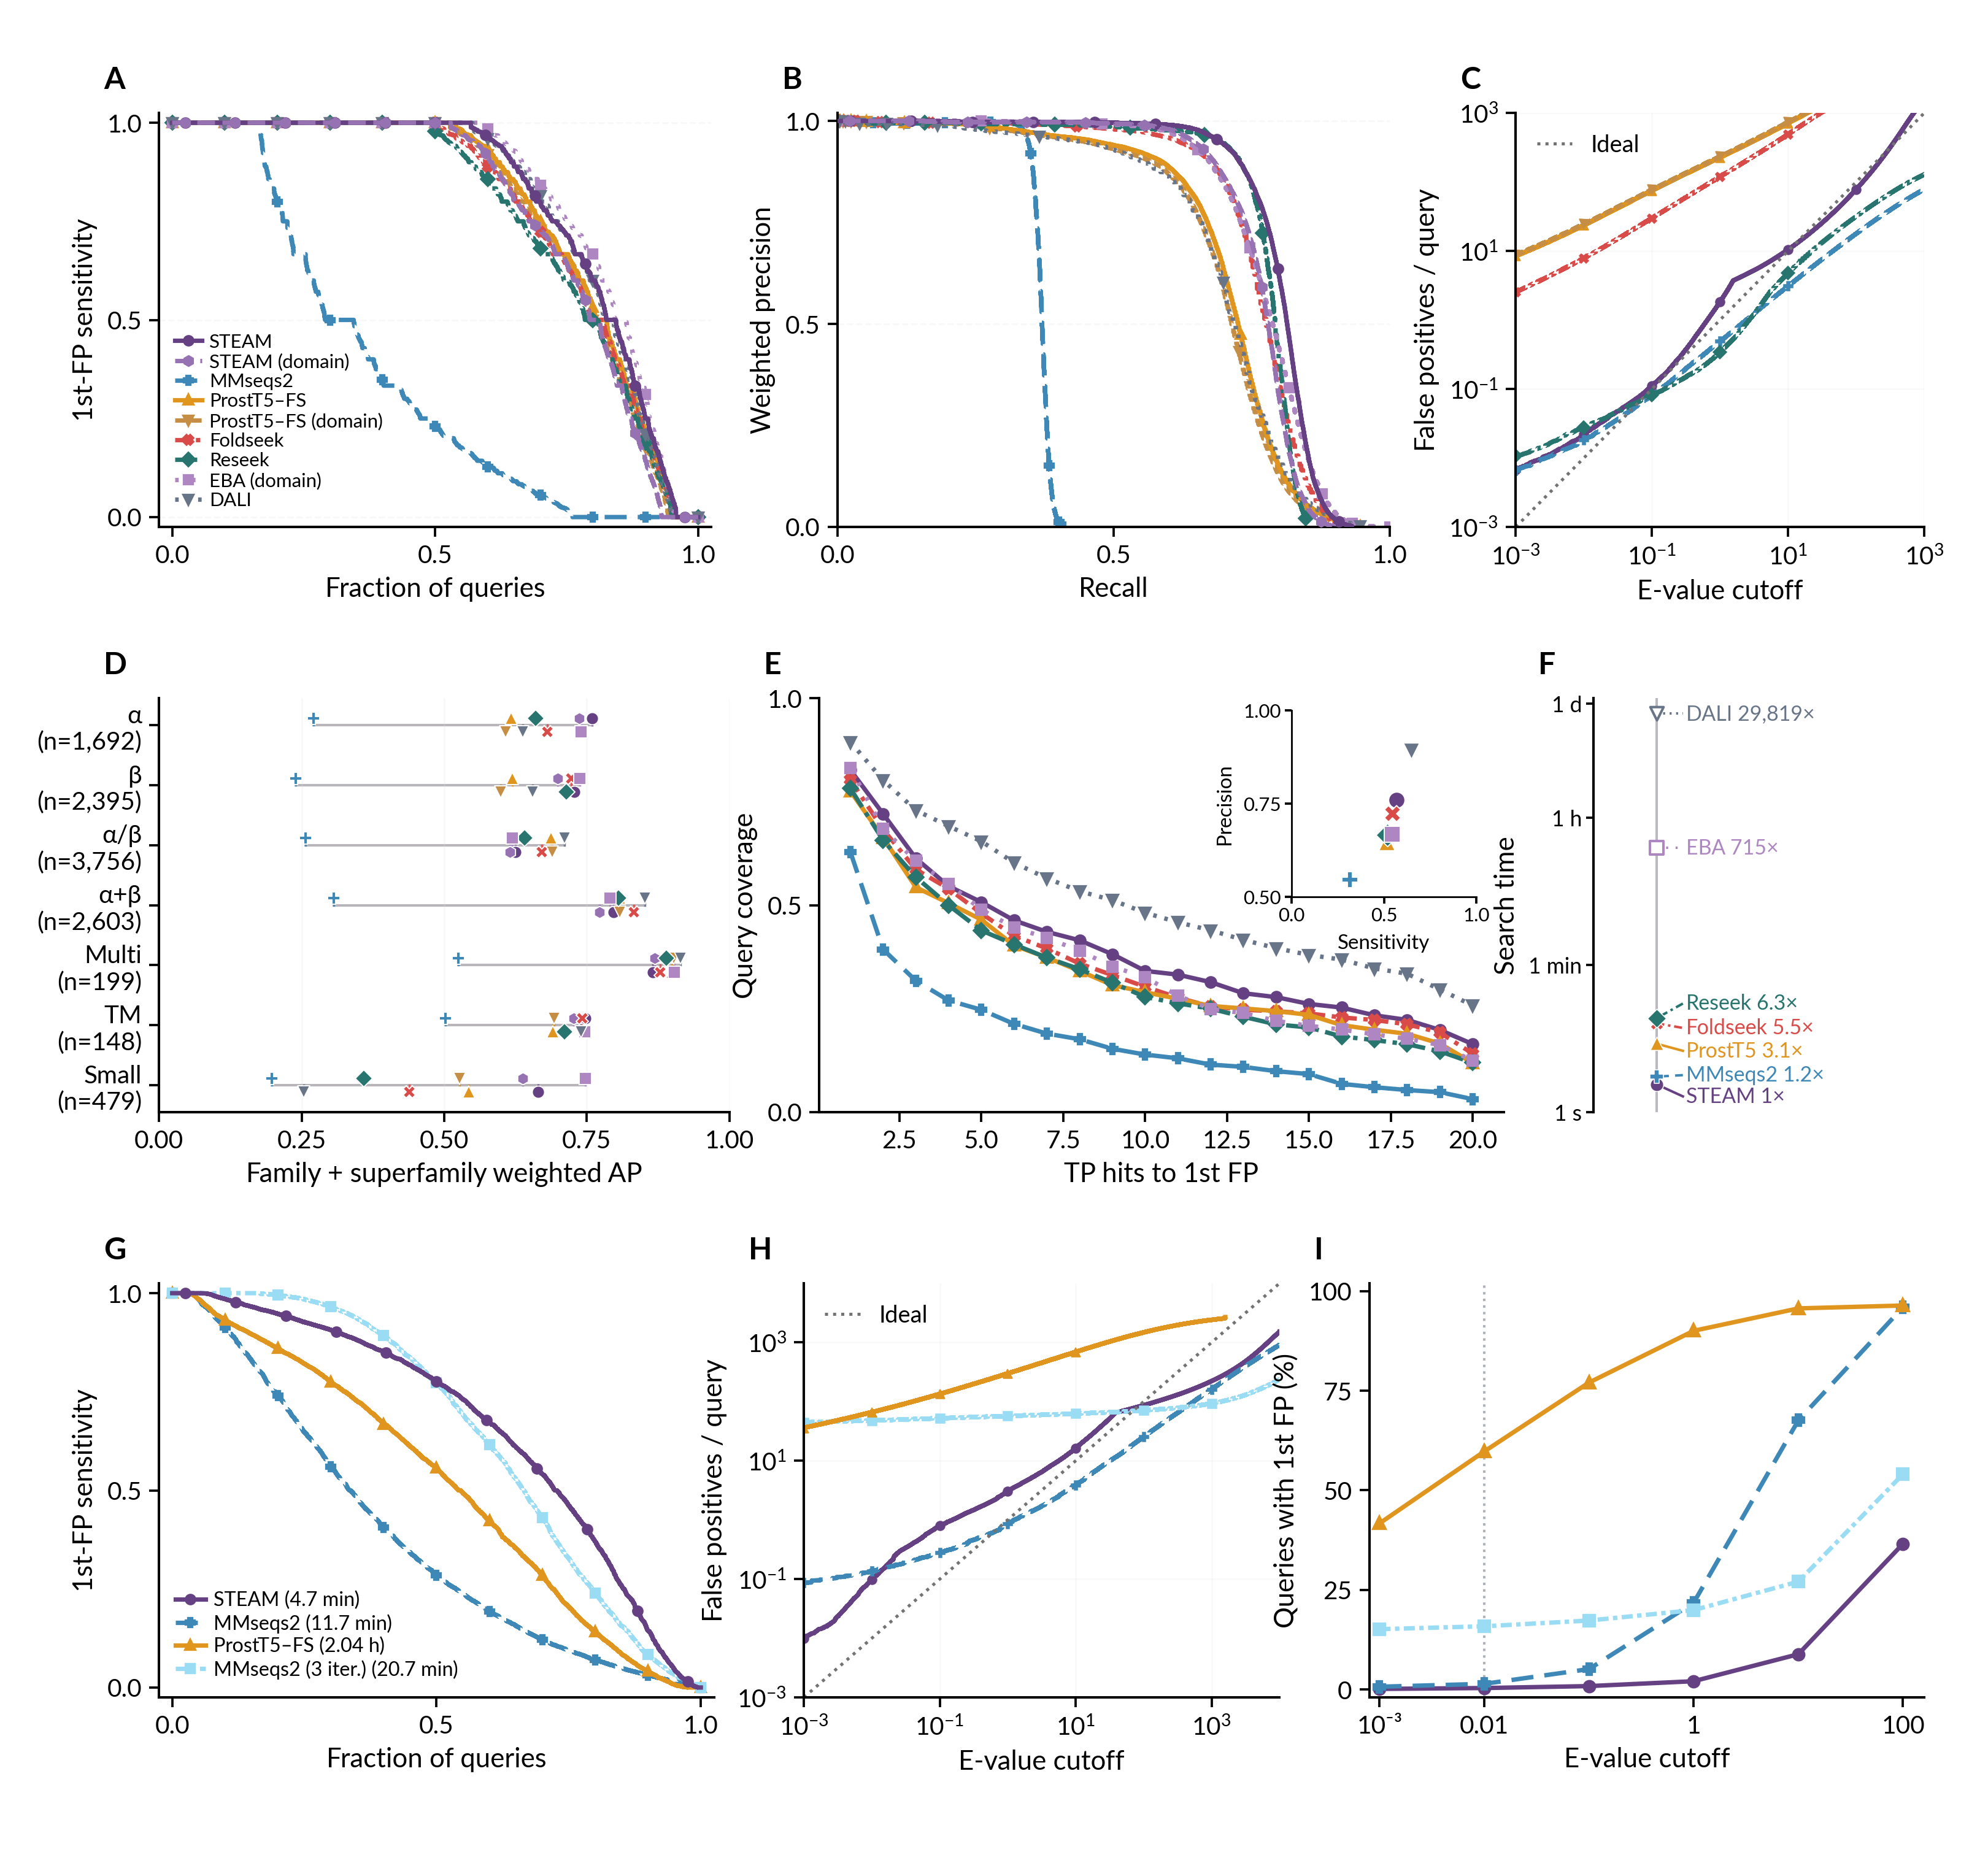

In [8]:
def matched_mmmd_receipt(engine):
    receipt = read_json(MMMD_TIMING / (engine + "_matched/run.json"))
    return receipt

def matched_mmmd_table(engine, mode, filename):
    folder = MMMD_MATCHED / engine / mode
    return folder / filename

def load_mmmd_metrics():
    results = {}
    for engine, label in (("steam", "STEAM"), ("mmseqs", "MMseqs2")):
        path = (REFRESH / 'mmseqs_multidomain/steam/metrics.json' if engine == 'steam'
                else matched_mmmd_table(engine, 'one_pass', 'metrics.json'))
        results[label] = read_json(path)
    results["ProstT5–Foldseek"] = read_json(CANON / "mmseqs_multidomain/prostt5-foldseek/metrics.json")
    results[ITER3_LABEL] = read_json(ITER3_TABLES/'metrics.json')
    return results

def draw_mmmd_G(axis):
    for label, metric in load_mmmd_metrics().items():
        if label == "ProstT5–Foldseek":
            seconds = read_json(SEARCH / "mmseqs_multidomain/prostt5_foldseek/run.json")["seconds"]["search"]
        elif label == 'STEAM':
            seconds = read_json(REFRESH / 'mmseqs_multidomain/steam/run.json')['seconds']['search']
        elif label == ITER3_LABEL:
            seconds = ITER3_RUN['methods']['three_pass']['seconds']
        else:
            seconds = matched_mmmd_receipt('mmseqs')['methods']['one_pass']['seconds']
        values = np.sort([row["sensitivity"] for row in metric["levels"]["family"]["per_query"].values()
                          if row["sensitivity"] is not None])[::-1]
        line = step(axis, np.arange(len(values)+1)/len(values), np.r_[values, 0.], label)
        duration = f"{seconds/60:.1f} min" if seconds < 3600 else f"{seconds/3600:.2f} h"
        line.set_label(f"{label.replace('–Foldseek', '–FS')} ({duration})")
    axis.set(xlim=(-.025, 1.025), ylim=(-.025, 1.025),
             xlabel="Fraction of queries", ylabel="1st-FP sensitivity")
    axis.set_xticks([0, .5, 1]); axis.set_yticks([0, .5, 1])
    axis.legend(frameon=False, fontsize=5.2, loc="lower left", bbox_to_anchor=(.015,.025),
                borderaxespad=0, handlelength=1.5, handletextpad=.4, labelspacing=.20)

def matched_mmmd_evalues(engine, mode):
    curve = pd.read_csv(matched_mmmd_table(engine, mode, "calibration.tsv"), sep="\t")
    points = pd.read_csv(matched_mmmd_table(engine, mode, "operating_points.tsv"), sep="\t")
    return {"predicted_errors_per_query": curve.evalue_cutoff.tolist(),
            "observed_errors_per_query": curve.observed_errors_per_query.tolist(),
            "operating_points": points.to_dict("records")}

def load_mmmd_evalues():
    results = {"ProstT5–Foldseek": read_json(CANON / "mmseqs_multidomain/prostt5-foldseek/evalues.json")}
    for engine, label in (("steam", "STEAM"), ("mmseqs", "MMseqs2")):
        results[label] = (read_json(REFRESH / 'mmseqs_multidomain/steam/evalues.json')
                          if engine == 'steam' else matched_mmmd_evalues(engine, 'one_pass'))
    curve = pd.read_csv(ITER3_TABLES/'calibration.tsv',sep='\t')
    points = pd.read_csv(ITER3_TABLES/'operating_points.tsv',sep='\t')
    results[ITER3_LABEL] = dict(predicted_errors_per_query=curve.evalue_cutoff.tolist(),
        observed_errors_per_query=curve.observed_errors_per_query.tolist(),operating_points=points.to_dict('records'))
    return results

def draw_first_fp_I(axis):
    for engine, label in (("steam", "STEAM"), ("mmseqs", "MMseqs2")):
        if engine == 'steam':
            source = read_json(REFRESH / 'mmseqs_multidomain/first_fp_types/by_evalue_summary.json')
            counts = source['methods']['steam']['counts']
            cuts = [.001, .01, .1, 1, 10, 100]
            points = pd.DataFrame({'evalue_cutoff': cuts, 'queries_with_fp_percent':
                [(6370-counts[f'{cut:g}'].get('none', 0))/6370*100 for cut in cuts]})
        else:
            points = pd.read_csv(matched_mmmd_table(engine, 'one_pass', 'operating_points.tsv'), sep='\t')
        points = points.loc[points.evalue_cutoff.le(100)]
        axis.plot(points.evalue_cutoff, points.queries_with_fp_percent, color=COLORS[label],
                  linestyle=DASHES[label], marker=MARKERS[label], markersize=2.5, linewidth=1.15, label=label)
    points = pd.read_csv(ITER3_TABLES/'operating_points.tsv',sep='\t')
    points = points.loc[points.evalue_cutoff.le(100)]
    axis.plot(points.evalue_cutoff,points.queries_with_fp_percent,color=COLORS[ITER3_LABEL],
              linestyle=DASHES[ITER3_LABEL],marker=MARKERS[ITER3_LABEL],markersize=2.5,linewidth=1.15,label=ITER3_LABEL)
    baseline = read_json(CANON / "mmseqs_multidomain/first_fp_types/by_evalue_summary.json")
    cuts = np.array([.001, .01, .1, 1, 10, 100])
    counts = baseline["methods"]["prostt5_foldseek"]["counts"]
    fractions = [(6370-counts[f"{cut:g}"].get("none", 0))/6370*100 for cut in cuts]
    label = "ProstT5–Foldseek"
    axis.plot(cuts, fractions, color=COLORS[label], linestyle=DASHES[label],
              marker=MARKERS[label], markersize=2.5, linewidth=1.15, label="ProstT5–FS")
    axis.axvline(.01, color="#aeb3ba", linewidth=.65, linestyle=":", zorder=0)
    axis.set(xscale="log", xlim=(8e-4, 160), ylim=(-2,102),
             xlabel="E-value cutoff", ylabel="Queries with 1st FP (%)")
    axis.set_xticks([.001,.01,1,100], ["10⁻³","0.01","1","100"])
    axis.set_yticks([0,25,50,75,100]); axis.minorticks_off()

render()